# Série 2 — Prédiction des tsunamis : Random Forest vs XGBoost
**Objectif :** prédire si un séisme a déclenché un tsunami (`tsunami` = 1) ou non (`tsunami` = 0) à partir de ses caractéristiques (magnitude, intensités, profondeur, localisation, qualité de la mesure, date…). Il s'agit d'un problème de **classification binaire** ; on entraîne et on compare **Random Forest** et **XGBoost**.

## 1. Importation des bibliothèques et des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_val_score)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, classification_report)
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("earthquake_data_tsunami.csv")
print(df.shape)
df.head()

(782, 13)


,magnitude,cdi,mmi,sig,nst,dmin,gap,depth,latitude,longitude,Year,Month,tsunami
0,7.0,8,7,768,117,0.509,17.0,14.000,-9.7963,159.596,2022,11,1
1,6.9,4,4,735,99,2.229,34.0,25.000,-4.9559,100.738,2022,11,0
2,7.0,3,3,755,147,3.125,18.0,579.000,-20.0508,-178.346,2022,11,1
3,7.3,5,5,833,149,1.865,21.0,37.000,-19.2918,-172.129,2022,11,1
4,6.6,0,2,670,131,4.998,27.0,624.464,-25.5948,178.278,2022,11,1


Description des variables : `magnitude`, `cdi` (intensité ressentie déclarée), `mmi` (intensité instrumentale), `sig` (score de significativité USGS), `nst` (nombre de stations), `dmin` (distance à la station la plus proche), `gap` (écart azimutal), `depth` (profondeur en km), `latitude`/`longitude`, `Year`/`Month` et **`tsunami` (cible, 0/1)**.

## 2. Nettoyage et analyse exploratoire

### 2.1 Nettoyage : types, valeurs manquantes, doublons

In [3]:
df.info()
print("\nValeurs manquantes par colonne :\n", df.isna().sum())
print("\nLignes dupliquées :", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 782 entries, 0 to 781
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   magnitude  782 non-null    float64
 1   cdi        782 non-null    int64  
 2   mmi        782 non-null    int64  
 3   sig        782 non-null    int64  
 4   nst        782 non-null    int64  
 5   dmin       782 non-null    float64
 6   gap        782 non-null    float64
 7   depth      782 non-null    float64
 8   latitude   782 non-null    float64
 9   longitude  782 non-null    float64
 10  Year       782 non-null    int64  
 11  Month      782 non-null    int64  
 12  tsunami    782 non-null    int64  
dtypes: float64(6), int64(7)
memory usage: 79.5 KB

Valeurs manquantes par colonne :
 magnitude    0
cdi          0
mmi          0
sig          0
nst          0
dmin         0
gap          0
depth        0
latitude     0
longitude    0
Year         0
Month        0
tsunami      0
dtype: int64



### 2.2 Équilibre des classes

,effectif,proportion
tsunami,,
Pas de tsunami,478,0.611
Tsunami,304,0.389


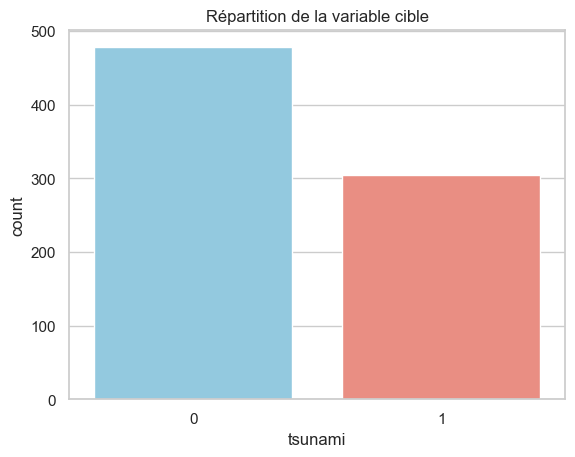

In [4]:
counts = df["tsunami"].value_counts().rename({0: "Pas de tsunami", 1: "Tsunami"})
display(pd.DataFrame({"effectif": counts, "proportion": (counts / len(df)).round(3)}))
sns.countplot(x="tsunami", data=df, palette=["skyblue", "salmon"])
plt.title("Répartition de la variable cible"); plt.show()

Les classes sont raisonnablement équilibrées (≈ 61 % / 39 %) : l'exactitude (*accuracy*) reste interprétable, mais on suivra aussi le **rappel**, la **précision**, le **F1** et l'**AUC**. Une baseline qui prédit toujours « pas de tsunami » atteint déjà ≈ 61 % d'exactitude : c'est le seuil à dépasser.

### 2.3 Statistiques descriptives

In [5]:
display(df.describe().T.round(3))
print("Asymétrie (skewness) :")
display(df.skew().round(3).to_frame("skew").T)

,count,mean,std,min,25%,50%,75%,max
magnitude,782.0,6.941,0.446,6.500,6.600,6.800,7.100,9.100
cdi,782.0,4.334,3.170,0.000,0.000,5.000,7.000,9.000
mmi,782.0,5.964,1.463,1.000,5.000,6.000,7.000,9.000
sig,782.0,870.109,322.465,650.000,691.000,754.000,909.750,2910.000
nst,782.0,230.251,250.188,0.000,0.000,140.000,445.000,934.000
dmin,782.0,1.326,2.219,0.000,0.000,0.000,1.863,17.654
gap,782.0,25.039,24.225,0.000,14.625,20.000,30.000,239.000
depth,782.0,75.883,137.277,2.700,14.000,26.295,49.750,670.810
latitude,782.0,3.538,27.303,-61.848,-14.596,-2.572,24.655,71.631
longitude,782.0,52.609,117.899,-179.968,-71.668,109.426,148.941,179.662


Asymétrie (skewness) :


,magnitude,cdi,mmi,sig,nst,dmin,gap,depth,latitude,longitude,Year,Month,tsunami
skew,1.444,-0.197,-0.25,3.084,0.533,2.605,4.669,3.025,0.201,-0.703,-0.192,-0.068,0.457


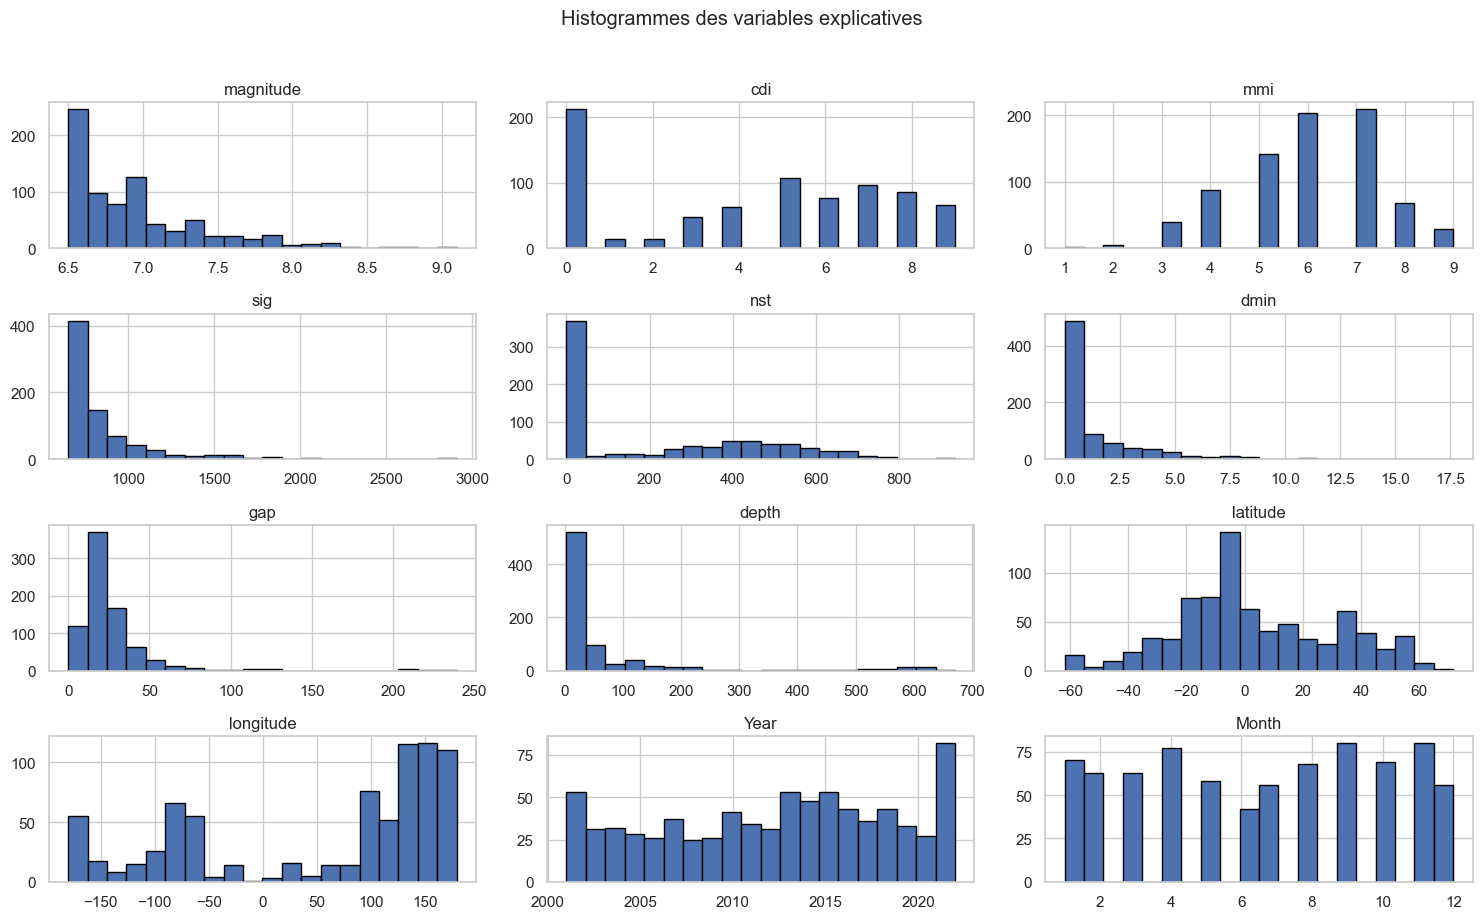

In [6]:
df.drop(columns="tsunami").hist(bins=20, figsize=(15, 9), edgecolor="black")
plt.suptitle("Histogrammes des variables explicatives", y=1.02)
plt.tight_layout(); plt.show()

### 2.4 Données aberrantes (règle de l'IQR)

In [7]:
num = df.drop(columns="tsunami")
Q1, Q3 = num.quantile(0.25), num.quantile(0.75)
IQR = Q3 - Q1
outliers = ((num < Q1 - 1.5*IQR) | (num > Q3 + 1.5*IQR)).sum()
print(outliers.to_frame("nb_outliers").T)

             magnitude  cdi  mmi  sig  nst  dmin  gap  depth  latitude  \
nb_outliers         37    0    1   73    0    61   48    139         0   

             longitude  Year  Month  
nb_outliers          0     0      0  


Les valeurs détectées (magnitudes extrêmes, séismes profonds, etc.) sont de vrais événements et non des erreurs ; on les **conserve** (les arbres y sont peu sensibles).

### 2.5 Analyse bivariée : variables explicatives vs `tsunami`

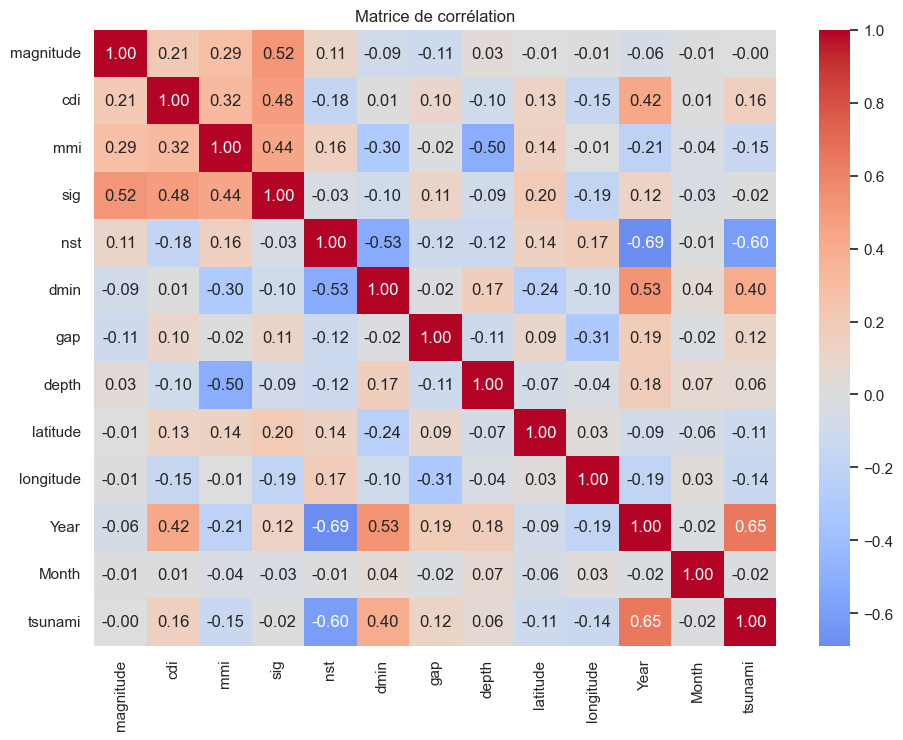

Corrélations avec tsunami :


,corr
Year,0.647
dmin,0.401
cdi,0.160
gap,0.116
depth,0.057
magnitude,-0.005
sig,-0.015
Month,-0.022
latitude,-0.113
longitude,-0.137


In [8]:
corr = df.corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation"); plt.show()
print("Corrélations avec tsunami :")
display(corr["tsunami"].drop("tsunami").sort_values(ascending=False).round(3).to_frame("corr"))

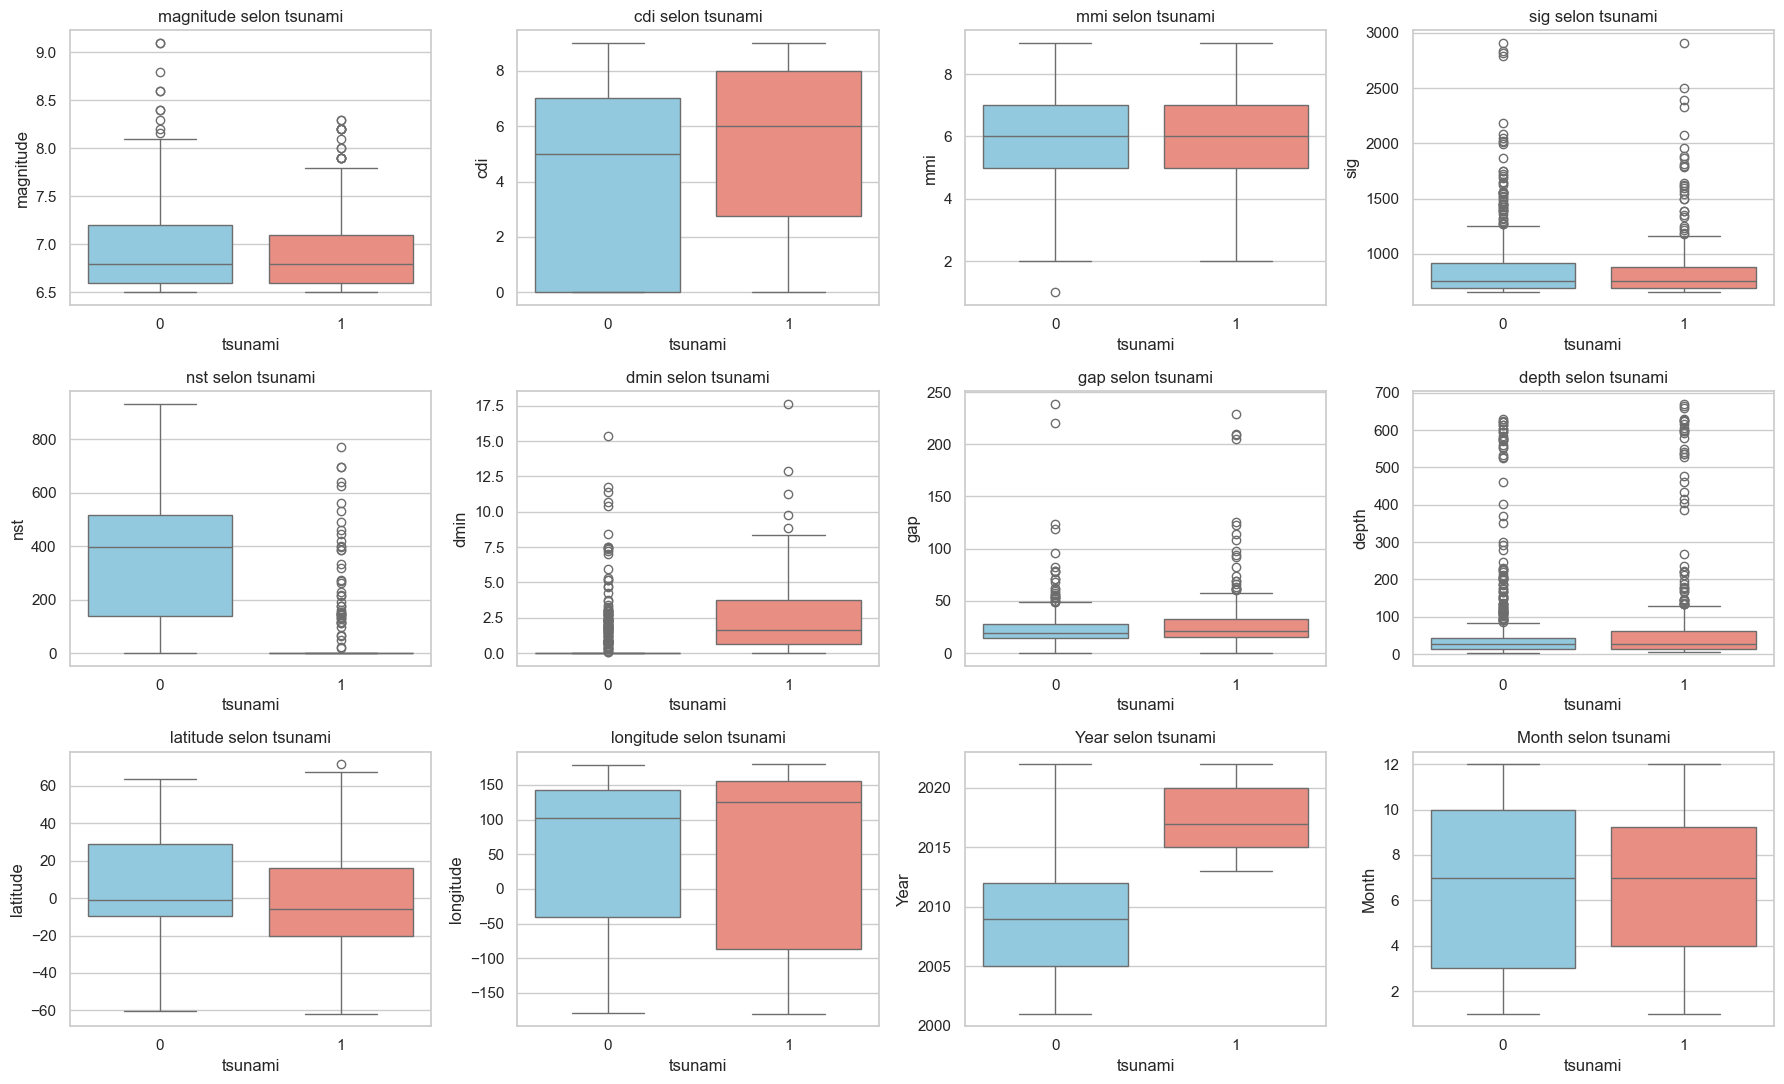

In [9]:
feats_plot = [c for c in df.columns if c != "tsunami"]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), feats_plot):
    sns.boxplot(x="tsunami", y=c, data=df, ax=ax, palette=["skyblue", "salmon"])
    ax.set_title(f"{c} selon tsunami")
plt.tight_layout(); plt.show()

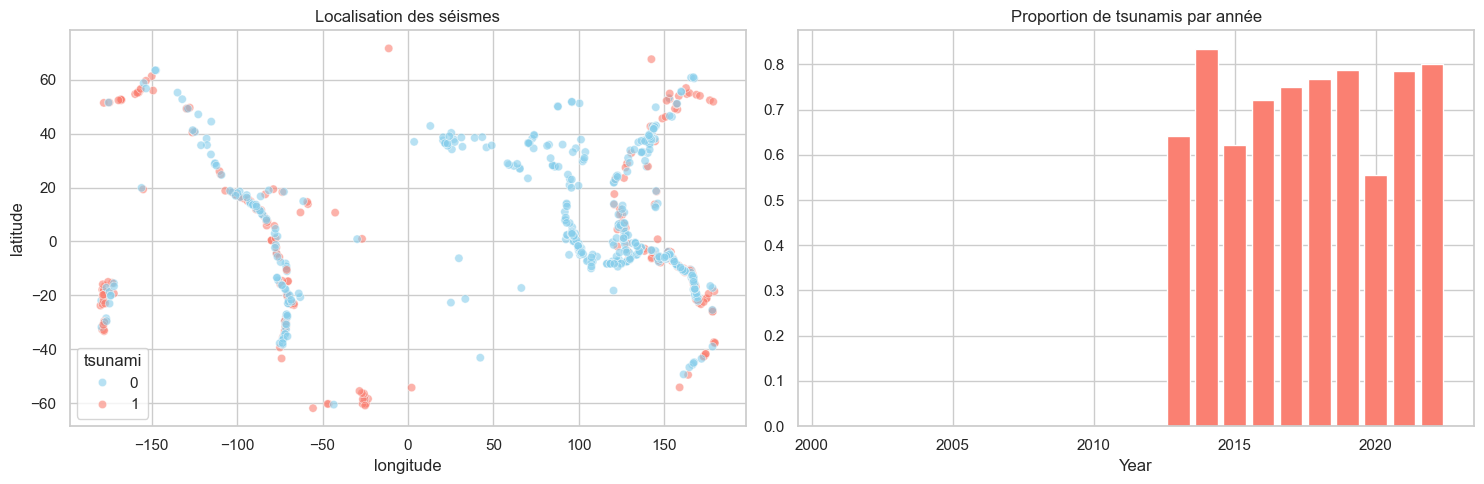

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=df, x="longitude", y="latitude", hue="tsunami",
                palette=["skyblue", "salmon"], alpha=.6, ax=axes[0])
axes[0].set_title("Localisation des séismes")
rate = df.groupby("Year")["tsunami"].mean()
axes[1].bar(rate.index, rate.values, color="salmon")
axes[1].set_title("Proportion de tsunamis par année"); axes[1].set_xlabel("Year")
plt.tight_layout(); plt.show()

**Observations :** la magnitude seule ne distingue presque pas les deux classes (corrélation ≈ 0). En revanche, `nst`, `dmin` et surtout `Year` sont fortement liés à `tsunami`. Cela est suspect : l'année et le nombre de stations reflètent probablement l'**évolution du réseau de mesure et des pratiques de déclaration**, plus que la physique des séismes. On vérifiera cette hypothèse en section 10.

## 3. Séparation X / y

Les modèles à base d'arbres sont invariants aux transformations monotones : **aucune standardisation n'est nécessaire**.

In [11]:
features = [c for c in df.columns if c != "tsunami"]
X = df[features]
y = df["tsunami"]
print("Variables explicatives :", features)

Variables explicatives : ['magnitude', 'cdi', 'mmi', 'sig', 'nst', 'dmin', 'gap', 'depth', 'latitude', 'longitude', 'Year', 'Month']


## 4. Séparation entraînement / test (80 % / 20 %, stratifiée)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(X_train.shape, X_test.shape)
print("Proportion de tsunamis — train :", round(y_train.mean(), 3), "| test :", round(y_test.mean(), 3))

(625, 12) (157, 12)
Proportion de tsunamis — train : 0.389 | test : 0.389


In [13]:
results = {}
def evaluate(name, model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Précision": precision_score(y_test, pred, zero_division=0),
        "Rappel": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "AUC ROC": roc_auc_score(y_test, proba),
        "AUC PR": average_precision_score(y_test, proba),
        "Accuracy train": accuracy_score(y_train, model.predict(X_train)),
    }
    return pd.Series(results[name]).round(4)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 5. Modèle de référence (baseline)

Un modèle qui prédit toujours la classe majoritaire : tout modèle utile doit faire mieux.

In [14]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
display(evaluate("Baseline (classe majoritaire)", dummy))

Accuracy          0.6115
Précision         0.0000
Rappel            0.0000
F1                0.0000
AUC ROC           0.5000
AUC PR            0.3885
Accuracy train    0.6112
dtype: float64

## 6. Random Forest

### 6.1 Random Forest avec hyperparamètres par défaut

In [15]:
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
display(evaluate("Random Forest (défaut)", rf))

Accuracy          0.9299
Précision         0.8788
Rappel            0.9508
F1                0.9134
AUC ROC           0.9641
AUC PR            0.9015
Accuracy train    1.0000
dtype: float64

### 6.2 Random Forest avec optimisation des hyperparamètres (validation croisée, score = AUC ROC)

In [16]:
rf_grid = {
    "n_estimators": [200, 400, 600],
    "max_depth": [None, 5, 8, 12],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", 0.5, 0.8],
    "class_weight": [None, "balanced"],
}
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), rf_grid, n_iter=30,
    cv=cv, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
print("Meilleurs hyperparamètres :", rf_search.best_params_)
print("AUC ROC CV :", round(rf_search.best_score_, 4))
rf_best = rf_search.best_estimator_
display(evaluate("Random Forest (optimisé)", rf_best))

Meilleurs hyperparamètres : {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 12, 'class_weight': 'balanced'}
AUC ROC CV : 0.9732


Accuracy          0.9427
Précision         0.8939
Rappel            0.9672
F1                0.9291
AUC ROC           0.9672
AUC PR            0.9214
Accuracy train    0.9840
dtype: float64

## 7. XGBoost

### 7.1 XGBoost avec hyperparamètres par défaut

In [17]:
xgb = XGBClassifier(n_estimators=300, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
display(evaluate("XGBoost (défaut)", xgb))

Accuracy          0.9427
Précision         0.9062
Rappel            0.9508
F1                0.9280
AUC ROC           0.9664
AUC PR            0.9071
Accuracy train    1.0000
dtype: float64

### 7.2 XGBoost avec optimisation des hyperparamètres (validation croisée, score = AUC ROC)

In [18]:
xgb_grid = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 6],
    "min_child_weight": [1, 3, 5, 10],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_lambda": [0.5, 1, 5, 10],
}
xgb_search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1), xgb_grid, n_iter=60,
    cv=cv, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
print("Meilleurs hyperparamètres :", xgb_search.best_params_)
print("AUC ROC CV :", round(xgb_search.best_score_, 4))
xgb_best = xgb_search.best_estimator_
display(evaluate("XGBoost (optimisé)", xgb_best))

Meilleurs hyperparamètres : {'subsample': 1.0, 'reg_lambda': 10, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
AUC ROC CV : 0.9742


Accuracy          0.9363
Précision         0.9048
Rappel            0.9344
F1                0.9194
AUC ROC           0.9636
AUC PR            0.9004
Accuracy train    0.9936
dtype: float64

## 8. Comparaison des modèles

,Accuracy,Précision,Rappel,F1,AUC ROC,AUC PR,Accuracy train
Random Forest (optimisé),0.9427,0.8939,0.9672,0.9291,0.9672,0.9214,0.9840
XGBoost (défaut),0.9427,0.9062,0.9508,0.9280,0.9664,0.9071,1.0000
Random Forest (défaut),0.9299,0.8788,0.9508,0.9134,0.9641,0.9015,1.0000
XGBoost (optimisé),0.9363,0.9048,0.9344,0.9194,0.9636,0.9004,0.9936
Baseline (classe majoritaire),0.6115,0.0000,0.0000,0.0000,0.5000,0.3885,0.6112


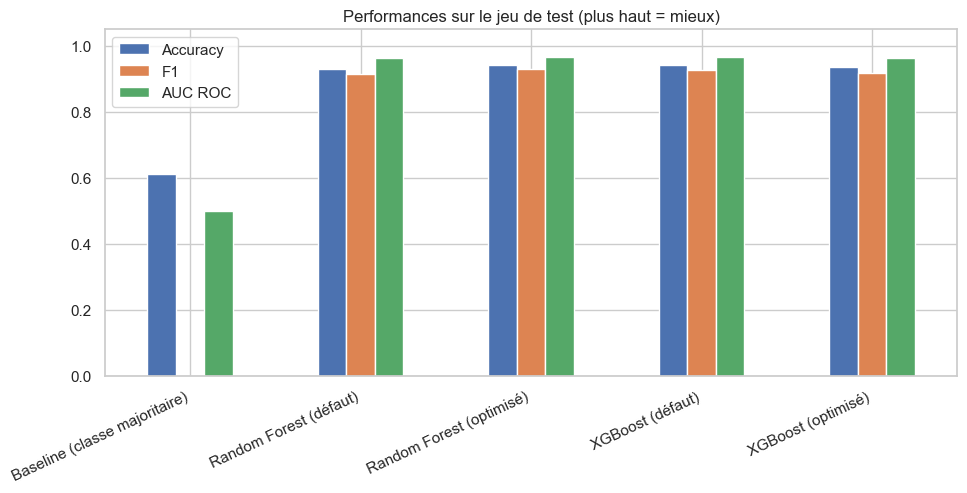

In [19]:
comp = pd.DataFrame(results).T.round(4)
display(comp.sort_values("AUC ROC", ascending=False))
comp[["Accuracy", "F1", "AUC ROC"]].plot(kind="bar", figsize=(11, 4.5))
plt.title("Performances sur le jeu de test (plus haut = mieux)")
plt.xticks(rotation=25, ha="right"); plt.ylim(0, 1.05); plt.show()

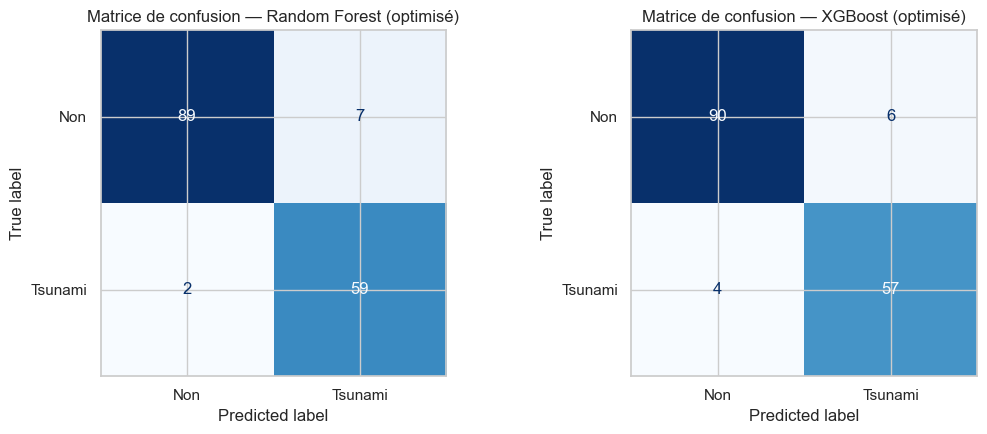

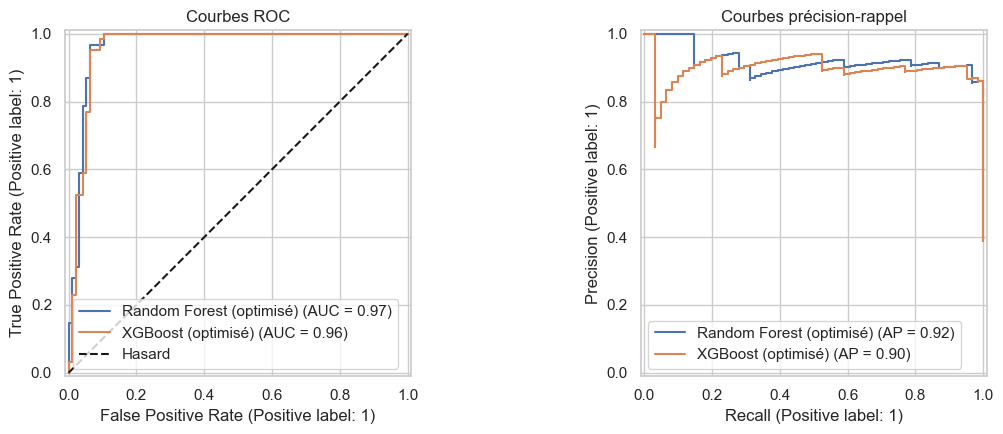

In [20]:
models_plot = {"Random Forest (optimisé)": rf_best, "XGBoost (optimisé)": xgb_best}
short = {"Random Forest (optimisé)": "RF", "XGBoost (optimisé)": "XGB"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, m) in zip(axes, models_plot.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["Non", "Tsunami"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Matrice de confusion — {name}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, m in models_plot.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", label="Hasard"); axes[0].legend(); axes[0].set_title("Courbes ROC")
axes[1].set_title("Courbes précision-rappel")
plt.tight_layout(); plt.show()

In [21]:
for name, m in models_plot.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, m.predict(X_test), target_names=["Pas de tsunami", "Tsunami"], digits=3))

=== Random Forest (optimisé) ===
                precision    recall  f1-score   support

Pas de tsunami      0.978     0.927     0.952        96
       Tsunami      0.894     0.967     0.929        61

      accuracy                          0.943       157
     macro avg      0.936     0.947     0.941       157
  weighted avg      0.945     0.943     0.943       157

=== XGBoost (optimisé) ===
                precision    recall  f1-score   support

Pas de tsunami      0.957     0.938     0.947        96
       Tsunami      0.905     0.934     0.919        61

      accuracy                          0.936       157
     macro avg      0.931     0.936     0.933       157
  weighted avg      0.937     0.936     0.936       157



### 8.1 Importance des variables

,RF — impureté,XGB — gain,RF — permutation (ΔAUC),XGB — permutation (ΔAUC)
Year,0.4297,0.6521,0.2408,0.2346
longitude,0.1461,0.0950,0.0561,0.0818
nst,0.1273,0.0343,-0.0017,0.0000
dmin,0.1141,0.0252,0.0018,0.0035
latitude,0.0615,0.0422,-0.0022,-0.0011
depth,0.0316,0.0291,0.0007,0.0002
sig,0.0212,0.0217,-0.0014,-0.0010
gap,0.0209,0.0128,-0.0021,-0.0013
magnitude,0.0142,0.0357,-0.0004,-0.0017
mmi,0.0121,0.0173,-0.0005,-0.0002


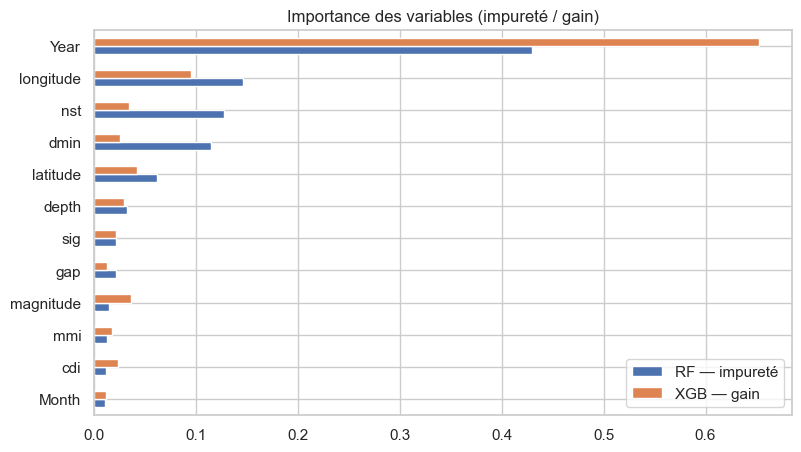

In [22]:
imp = pd.DataFrame({"RF — impureté": rf_best.feature_importances_,
                    "XGB — gain": xgb_best.feature_importances_}, index=features)
perm = {}
for name, m in models_plot.items():
    r = permutation_importance(m, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="roc_auc")
    perm[short[name] + " — permutation (ΔAUC)"] = r.importances_mean
imp = imp.join(pd.DataFrame(perm, index=features)).round(4)
display(imp.sort_values("RF — impureté", ascending=False))
imp[["RF — impureté", "XGB — gain"]].sort_values("RF — impureté").plot(kind="barh", figsize=(9, 5))
plt.title("Importance des variables (impureté / gain)"); plt.show()

### 8.2 Validation croisée stratifiée 10-fold sur l'ensemble des données

Un seul split de test (≈ 157 séismes) est peu fiable pour départager deux modèles proches ; la validation croisée donne une estimation plus stable.

In [23]:
cv10 = StratifiedKFold(10, shuffle=True, random_state=0)
cv_models = {"Baseline (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
             "Random Forest (optimisé)": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **rf_search.best_params_),
             "XGBoost (optimisé)": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1, **xgb_search.best_params_)}
rows = {}
for n, m in cv_models.items():
    auc = cross_val_score(m, X, y, cv=cv10, scoring="roc_auc")
    acc = cross_val_score(m, X, y, cv=cv10, scoring="accuracy")
    f1 = cross_val_score(m, X, y, cv=cv10, scoring="f1")
    rows[n] = {"AUC ROC CV": auc.mean(), "écart-type AUC": auc.std(), "Accuracy CV": acc.mean(), "F1 CV": f1.mean()}
cv_comp = pd.DataFrame(rows).T.round(4)
cv_comp.sort_values("AUC ROC CV", ascending=False)

,AUC ROC CV,écart-type AUC,Accuracy CV,F1 CV
Random Forest (optimisé),0.9712,0.0166,0.9361,0.9232
XGBoost (optimisé),0.9704,0.0173,0.9284,0.9116
Baseline (classe majoritaire),0.5000,0.0000,0.6113,0.0000


## 9. Seuil de décision

Par défaut, un séisme est classé « tsunami » si la probabilité dépasse 0.5. Pour un système d'alerte, **manquer un vrai tsunami (faux négatif) est bien plus grave qu'une fausse alerte** ; on peut donc abaisser le seuil pour augmenter le rappel, au prix de la précision.

In [24]:
best_name_tmp = cv_comp.drop("Baseline (classe majoritaire)")["AUC ROC CV"].idxmax()
m = models_plot[best_name_tmp]
proba = m.predict_proba(X_test)[:, 1]
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    p = (proba >= t).astype(int)
    rows.append({"seuil": t, "Précision": precision_score(y_test, p, zero_division=0),
                 "Rappel": recall_score(y_test, p), "F1": f1_score(y_test, p),
                 "Faux négatifs": int(((p == 0) & (y_test == 1)).sum()),
                 "Fausses alertes": int(((p == 1) & (y_test == 0)).sum())})
print("Modèle :", best_name_tmp)
display(pd.DataFrame(rows).set_index("seuil").round(3))

Modèle : Random Forest (optimisé)


,Précision,Rappel,F1,Faux négatifs,Fausses alertes
seuil,,,,,
0.2,0.792,1.000,0.884,0,16
0.3,0.836,1.000,0.910,0,12
0.4,0.868,0.967,0.915,2,9
0.5,0.894,0.967,0.929,2,7
0.6,0.906,0.951,0.928,3,6


## 10. Robustesse : le modèle apprend-il la géophysique ou l'historique des mesures ?

On a vu que `Year` et `nst` sont fortement liées à `tsunami`. On ré-évalue (CV 10-fold, mêmes hyperparamètres) avec trois jeux de variables :
* **toutes** les variables ;
* **sans la date** (`Year`, `Month`) ;
* **géophysiques seulement** : `magnitude`, `depth`, `latitude`, `longitude`, `cdi`, `mmi`, `sig` (sans date ni caractéristiques du réseau de mesure `nst`, `dmin`, `gap`).

,,AUC ROC CV,Accuracy CV
Random Forest,toutes,0.9712,0.9361
XGBoost,toutes,0.9704,0.9284
Random Forest,sans date,0.9429,0.9054
XGBoost,sans date,0.9447,0.9054
Random Forest,géophysiques seulement,0.8192,0.7430
XGBoost,géophysiques seulement,0.8091,0.7187


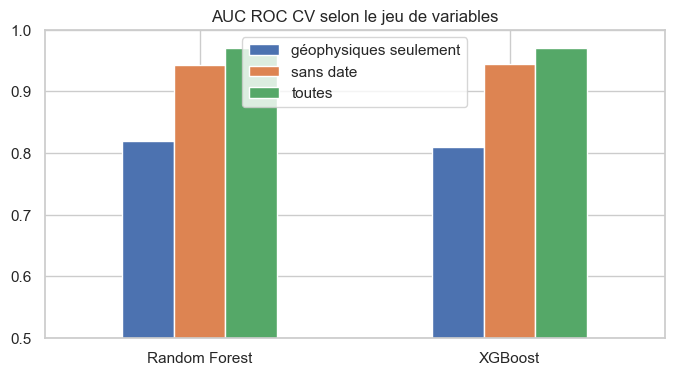

In [25]:
sets = {"toutes": features,
        "sans date": [f for f in features if f not in ("Year", "Month")],
        "géophysiques seulement": ["magnitude", "depth", "latitude", "longitude", "cdi", "mmi", "sig"]}
rows = {}
for label, fs in sets.items():
    for n, m in {"Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **rf_search.best_params_),
                 "XGBoost": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1, **xgb_search.best_params_)}.items():
        rows[(n, label)] = {"AUC ROC CV": cross_val_score(m, df[fs], y, cv=cv10, scoring="roc_auc").mean(),
                            "Accuracy CV": cross_val_score(m, df[fs], y, cv=cv10, scoring="accuracy").mean()}
rob = pd.DataFrame(rows).T.round(4)
display(rob)
rob["AUC ROC CV"].unstack().plot(kind="bar", figsize=(8, 4)); plt.ylim(0.5, 1.0)
plt.title("AUC ROC CV selon le jeu de variables"); plt.xticks(rotation=0); plt.show()

In [26]:
# Validation temporelle : entraînement sur les années anciennes, test sur les plus récentes
cut = df["Year"].quantile(0.8)
tr, te = df[df["Year"] <= cut], df[df["Year"] > cut]
rows = {}
for label, fs in sets.items():
    for n, m in {"Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **rf_search.best_params_),
                 "XGBoost": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1, **xgb_search.best_params_)}.items():
        m.fit(tr[fs], tr["tsunami"])
        p = m.predict_proba(te[fs])[:, 1]
        rows[(n, label)] = {"AUC ROC": roc_auc_score(te["tsunami"], p),
                            "Accuracy": accuracy_score(te["tsunami"], p >= 0.5)}
print(f"Entraînement : Year ≤ {int(cut)} ({len(tr)} séismes) | Test : Year > {int(cut)} ({len(te)} séismes, {te['tsunami'].mean():.0%} de tsunamis)")
pd.DataFrame(rows).T.round(4)

Entraînement : Year ≤ 2018 (640 séismes) | Test : Year > 2018 (142 séismes, 75% de tsunamis)


,,AUC ROC,Accuracy
Random Forest,toutes,0.8664,0.8239
XGBoost,toutes,0.8608,0.8521
Random Forest,sans date,0.8433,0.7465
XGBoost,sans date,0.8623,0.8099
Random Forest,géophysiques seulement,0.8299,0.5915
XGBoost,géophysiques seulement,0.8197,0.6056


## 11. Interprétation

* **Les deux modèles sont très performants en apparence.** Sur le jeu de test, Random Forest optimisé atteint une exactitude de 94.3 %, un F1 de 0.93 et une AUC de 0.967 ; XGBoost optimisé 93.0 %, 0.91 et 0.963. La baseline (toujours « pas de tsunami ») plafonne à 61 % d'exactitude et 0.50 d'AUC.
* **Random Forest vs XGBoost : quasi-égalité.** En validation croisée 10-fold, l'AUC est de 0.9712 (RF) contre 0.9707 (XGBoost), très en deçà de l'écart-type entre plis (≈ 0.017). Random Forest est légèrement devant sur l'exactitude (93.6 % vs 92.6 %) et le F1 (0.923 vs 0.908), mais la différence reste faible : c'est lui que le code retient, XGBoost restant une alternative équivalente.
* **Surapprentissage modéré :** les modèles par défaut mémorisent le train (exactitude train = 100 %). Après optimisation, l'écart train/test se réduit (≈ 98–99 % contre 93–94 %), mais subsiste.
* **Variable dominante : `Year`, pas la physique.** L'importance par permutation montre que retirer l'information `Year` fait chuter l'AUC d'environ 0.23–0.24, soit loin devant `longitude` (≈ 0.06–0.08), alors que la magnitude, la profondeur, `mmi` ou `cdi` ont une importance quasi nulle. La proportion de tsunamis dépend fortement de l'année dans ce jeu de données (elle atteint 75 % après 2018 contre 39 % globalement) : cela traduit très probablement la façon dont les données ont été collectées ou sélectionnées, et non un phénomène géophysique.
* **Performance réaliste :** sans la date, l'AUC CV tombe à ≈ 0.94 ; avec uniquement les variables géophysiques (magnitude, profondeur, position, intensités, `sig`), elle tombe à ≈ 0.81–0.82 (exactitude ≈ 73–74 %, contre 61 % pour la baseline). Le modèle reste utile, mais **les 97 % d'AUC annoncés surestiment la capacité réelle à prédire un tsunami** à partir des seules caractéristiques du séisme. La longitude joue un rôle réel (les tsunamis sont concentrés dans certaines zones, notamment la ceinture du Pacifique).
* **Validation temporelle :** en entraînant sur les années ≤ 2018 et en testant sur les plus récentes, l'AUC chute à ≈ 0.85–0.87 (toutes variables) et ≈ 0.81–0.83 (géophysiques seulement). Avec seulement les variables géophysiques, l'exactitude (≈ 58 %) est même inférieure à celle d'un modèle qui prédirait toujours « tsunami » (75 % sur cette période) : la distribution des classes change au cours du temps, ce qui dégrade les seuils de décision appris.
* **Seuil de décision :** pour un système d'alerte, on privilégie le rappel. Avec le Random Forest, un seuil de 0.3 élimine tous les faux négatifs du jeu de test (rappel = 100 %) au prix de 12 fausses alertes (contre 2 faux négatifs et 7 fausses alertes au seuil de 0.5).
* **Limites :** petit échantillon (782 séismes, magnitudes ≥ 6.5 uniquement), biais d'échantillonnage manifeste lié à `Year`, variables `cdi`/`mmi`/`sig` mesurées **après** l'événement (le modèle classe a posteriori, il ne prévoit pas), un seul jeu de test, et hyperparamètres choisis sur le train alors que la validation croisée 10-fold utilise toutes les données (légère optimisme). Pour une utilisation réelle, il faudrait des données plus complètes (type de faille, distance à la côte, bathymétrie, mécanisme au foyer).

## 12. Prédiction pour un nouveau séisme

In [27]:
best_name = cv_comp.drop("Baseline (classe majoritaire)")["AUC ROC CV"].idxmax()
final_model = {"Random Forest (optimisé)": rf_best, "XGBoost (optimisé)": xgb_best}[best_name]
print("Modèle retenu (meilleur AUC ROC en validation croisée) :", best_name)

# magnitude, cdi, mmi, sig, nst, dmin, gap, depth, latitude, longitude, Year, Month
new_quake = pd.DataFrame([[7.2, 6, 6, 800, 150, 1.5, 20, 30, -20.0, -70.0, 2022, 11]], columns=features)
p = final_model.predict_proba(new_quake)[0, 1]
print(f"Probabilité de tsunami : {p:.1%} -> prédiction : {'TSUNAMI' if p >= 0.5 else 'pas de tsunami'}")

Modèle retenu (meilleur AUC ROC en validation croisée) : Random Forest (optimisé)
Probabilité de tsunami : 92.7% -> prédiction : TSUNAMI


## 13. Sauvegarde du modèle final

Aucun `scaler` n'est nécessaire : on sauvegarde directement le modèle avec `joblib`, ainsi que la liste ordonnée des variables attendues.

In [28]:
joblib.dump({"model": final_model, "features": features}, "modele_final_tsunami.joblib")

# Vérification du rechargement
loaded = joblib.load("modele_final_tsunami.joblib")
print("Probabilité de tsunami (modèle rechargé) :",
      round(loaded["model"].predict_proba(new_quake[loaded["features"]])[0, 1], 3))

Probabilité de tsunami (modèle rechargé) : 0.927
